# Ablation template — fine-tuning depth of Model B

Template for the pre-registered experiment `experiments/ablation_finetune_depth/PROTOCOL.md`. It is a copy of `notebooks/05_MURA_ResNet18_FineTune.ipynb` (branch ARTEM, run `run_20261017T095546Z`) with one functional change: `CONFIG["trainable_layers"]` chooses which ResNet-18 blocks are trained. With `"all"` the notebook behaves exactly like Notebook 05.

| Arm | `trainable_layers` | Trainable parameters |
|---|---|---|
| S1 | `fc` | 513 |
| S2 | `layer4+fc` | 8,394,241 |
| S3 | `layer3+layer4+fc` | 10,493,953 |
| S4 | `all` | 11,177,025 |

Frozen blocks have `requires_grad = False`, are not passed to the optimizer, and their BatchNorm layers stay in `eval()` mode, so they keep the ImageNet statistics.

**How to run one arm**

1. In the Configuration cell set `seed` (23, 42 or 7) and `trainable_layers`. R0 is `"all"` with seed 23.
2. Runtime → Change runtime type → **T4 GPU**. The notebook stops on any other GPU.
3. Run all.
4. File → Save a copy in GitHub → branch `ARTEM`, path `experiments/ablation_finetune_depth/runs/05_<arm>_seed<N>.ipynb` (R0: `05_S4_seed23_R0.ipynb`), without the Colab badge.
5. Record the printed run id in `PROTOCOL.md` §14.

Do not edit this template between runs. Results do not enter Notebook 06a (protocol §11), and the official MURA `valid` split is not read.

# 05 — Model B: fine-tuned ResNet-18 (study level)

This notebook trains **Model B** for the MURA XR_WRIST project: an ImageNet ResNet-18 whose weights are all
fine-tuned on the internal training split.

Pipeline: each X-ray view → ResNet-18 → one logit → probability → **mean (or max) over the views of a study**
→ one study-level NORMAL / ABNORMAL probability. The loss is computed once per study, never per view.

**Inputs (read-only):** the clean manifests from Notebook 02 (`PREPROCESSED_WRIST`) and the raw MURA ZIP.
The official MURA `valid` split (locked test) is **not** read here.

**Outputs:** a new, time-stamped folder `DATA/RUNS_ARTEM/05_MODEL_B_FINETUNE/run_…/`.
No existing team file is modified or replaced.

Hyperparameters follow `configs/resnet18_finetune.yaml` in the repository.

In [270]:
import hashlib
import json
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")
print("Torch:", torch.__version__, "| Torchvision:", torchvision.__version__)
if not USE_AMP:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU before training.")

Device: cuda Tesla T4
Torch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130


In [271]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [272]:
from pathlib import Path
from datetime import datetime, timezone

# The team DATA folder is shared from the project owner's Drive. Members see it
# either through a "DATA" shortcut in My Drive or through the shared
# "Final Project DS23" shortcut. Both resolve to the same physical folder.
DRIVE_ROOT = Path("/content/drive/MyDrive")
DATA_DIR_CANDIDATES = [
    DRIVE_ROOT / "DATA",
    DRIVE_ROOT
    / "Final Project DS23"
    / "Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays"
    / "DATA",
]


def resolve_data_dir(candidates=DATA_DIR_CANDIDATES):
    for candidate in candidates:
        if (candidate / "MURA-v1.1_files.zip").exists() and (candidate / "WRIST_SPLITS").is_dir():
            return candidate
    raise FileNotFoundError(
        "Team DATA folder not found. Add a 'DATA' shortcut to My Drive or check "
        "that 'Final Project DS23' is in My Drive. Tried:\n"
        + "\n".join(str(c) for c in candidates)
    )


DATA_DIR = resolve_data_dir()
RAW_ZIP = DATA_DIR / "MURA-v1.1_files.zip"
SPLITS_DIR = DATA_DIR / "WRIST_SPLITS"            # read-only here (Notebook 01 output)
PREPROCESSING_DIR = DATA_DIR / "PREPROCESSED_WRIST"  # read-only here (Notebook 02 output)
MODEL_A_DIR = DATA_DIR / "BASELINE_MODEL_A"        # read-only here (Notebook 03 output)

# Shared-folder rule: this notebook never modifies or replaces existing team
# files. Everything it writes goes to a NEW run folder under RUNS_ARTEM.
RUN_ROOT = DATA_DIR / "RUNS_ARTEM"
STAGE_DIR = RUN_ROOT / "05_MODEL_B_FINETUNE"


def new_run_dir(stage_dir):
    run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
    run_dir = stage_dir / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    return run_dir


def out_path(run_dir, name):
    """Return a path inside this run's own folder; refuse anything else."""
    path = run_dir / name
    assert str(path).startswith(str(run_dir) + "/"), path
    assert not path.exists(), f"Refusing to overwrite: {path}"
    return path


print("Team DATA folder:", DATA_DIR)
print("Writes only under:", STAGE_DIR)

Team DATA folder: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA
Writes only under: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/RUNS_ARTEM/05_MODEL_B_FINETUNE


## Configuration

Values copied from `configs/resnet18_finetune.yaml`. `batch_size` counts **studies** (the number of views varies from study to study).
"auto" class weighting gives the ABNORMAL class the weight *n_normal / n_abnormal* of the internal training studies.

In [273]:
CONFIG = {
    "seed": 202,  # protocol seeds: 23, 42, 7 (stage 2 only: 101, 202)
    "trainable_layers": "layer4+fc",  # S1 "fc" | S2 "layer4+fc" | S3 "layer3+layer4+fc" | S4 "all"
    "experiment": "ablation_finetune_depth",
    "batch_size_studies": 8,
    "image_size": 224,
    "max_epochs": 15,
    "early_stopping_patience": 4,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "optimizer": "AdamW",
    "lr_scheduler": "ReduceLROnPlateau(mode=max, factor=0.5, patience=2) on validation AUROC",
    "class_weighting": "auto",
    "augmentation": {
        "horizontal_flip_probability": 0.0,
        "rotation_degrees": 7,
        "affine_translate": 0.03,
        "affine_scale": [0.95, 1.05],
        "brightness": 0.05,
    },
    "train_aggregation": "mean",
    "monitor": "validation AUROC, mean aggregation",
    "aggregation_candidates": ["mean", "max"],
    "mixed_precision": USE_AMP,
    "num_workers": min(4, os.cpu_count() or 1),
    "config_source": "configs/resnet18_finetune.yaml",
}

SEED = CONFIG["seed"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

assert torch.cuda.is_available() and "T4" in torch.cuda.get_device_name(0), "Protocol §4: select a T4 GPU (Runtime > Change runtime type)"
RUN_DIR = new_run_dir(STAGE_DIR)
print("This run writes to:", RUN_DIR)


def own_path(name):
    # Files this run owns (e.g. checkpoints that are updated during training).
    path = RUN_DIR / name
    assert str(path).startswith(str(RUN_DIR) + "/"), path
    return path

This run writes to: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/RUNS_ARTEM/05_MODEL_B_FINETUNE/run_20261020T215534Z


## Load the clean manifests (input contract)

Same checks as Notebook 03: required columns, binary labels, one label per study, no patient or study overlap
between train and validation, and no image from the official MURA `valid` folder.

In [274]:
TRAIN_MANIFEST = PREPROCESSING_DIR / "wrist_internal_train_clean.csv"
VALIDATION_MANIFEST = PREPROCESSING_DIR / "wrist_internal_val_clean.csv"
for required_path in (RAW_ZIP, TRAIN_MANIFEST, VALIDATION_MANIFEST):
    assert required_path.exists(), f"Not found: {required_path}"

train_views = pd.read_csv(TRAIN_MANIFEST)
validation_views = pd.read_csv(VALIDATION_MANIFEST)

PATH_CANDIDATES = ("image_path", "relative_path", "path", "file_name")
PATH_COLUMN = next((c for c in PATH_CANDIDATES if c in train_views.columns), None)
assert PATH_COLUMN is not None and PATH_COLUMN in validation_views.columns

for split_name, frame in {"train": train_views, "validation": validation_views}.items():
    missing = {"patient_id", "study_uid", "label_binary"} - set(frame.columns)
    assert not missing, f"{split_name} is missing {sorted(missing)}"
    assert frame["label_binary"].isin([0, 1]).all()
    assert frame.groupby("study_uid")["label_binary"].nunique().max() == 1
    paths = frame[PATH_COLUMN].astype(str).str.replace("\\", "/", regex=False)
    assert not paths.str.contains(r"(^|/)valid/", regex=True).any(), "Official MURA valid image found!"
    assert not paths.str.split("/").str[-1].str.startswith("._").any(), "AppleDouble file found"

assert set(train_views["patient_id"].astype(str)).isdisjoint(set(validation_views["patient_id"].astype(str)))
assert set(train_views["study_uid"].astype(str)).isdisjoint(set(validation_views["study_uid"].astype(str)))


def summarize(frame, name):
    studies = frame.drop_duplicates("study_uid")
    return {
        "split": name,
        "images": len(frame),
        "studies": studies["study_uid"].nunique(),
        "patients": studies["patient_id"].nunique(),
        "normal_studies": int((studies["label_binary"] == 0).sum()),
        "abnormal_studies": int((studies["label_binary"] == 1).sum()),
    }


split_summary = pd.DataFrame([summarize(train_views, "train"), summarize(validation_views, "validation")])
display(split_summary)
print("Input contract passed. Image path column:", PATH_COLUMN)

/tmp/ipykernel_1101/3254505279.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  assert not paths.str.contains(r"(^|/)valid/", regex=True).any(), "Official MURA valid image found!"
/tmp/ipykernel_1101/3254505279.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  assert not paths.str.contains(r"(^|/)valid/", regex=True).any(), "Official MURA valid image found!"


,split,images,studies,patients,normal_studies,abnormal_studies
0,train,7810,2769,2614,1712,1057
1,validation,1942,691,653,422,269


Input contract passed. Image path column: file_name


## Image transforms

Evaluation transform = Notebook 03. Training adds only the light augmentation from the config (no flips).

In [275]:
from PIL import Image, ImageOps
from torchvision import transforms
from torchvision.transforms import InterpolationMode


class PadToSquare:
    """Same padding rule as Notebooks 02 and 03 (black border, centred)."""

    def __call__(self, image):
        width, height = image.size
        side = max(width, height)
        left = (side - width) // 2
        top = (side - height) // 2
        right = side - width - left
        bottom = side - height - top
        return ImageOps.expand(image, border=(left, top, right, bottom), fill=0)


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMAGE_SIZE = 224


def _to_gray(image):
    return image.convert("L")


def _to_rgb(image):
    return image.convert("RGB")


# Identical to the evaluation transform of Notebook 03.
evaluation_transform = transforms.Compose([
    transforms.Lambda(_to_gray),
    PadToSquare(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.Lambda(_to_rgb),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [276]:
AUG = CONFIG["augmentation"]
training_transform = transforms.Compose([
    transforms.Lambda(_to_gray),
    PadToSquare(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.RandomAffine(
        degrees=AUG["rotation_degrees"],
        translate=(AUG["affine_translate"], AUG["affine_translate"]),
        scale=tuple(AUG["affine_scale"]),
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    transforms.ColorJitter(brightness=AUG["brightness"]),
    transforms.Lambda(_to_rgb),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print("Transforms ready.")

Transforms ready.


## Stage the images on the Colab disk

The ZIP is copied once to the local disk (faster than random reads from Drive). Nothing is written to Drive here.

In [277]:
import shutil
import time
import zipfile

LOCAL_ROOT = Path("/content/mura_local")
LOCAL_ZIP = LOCAL_ROOT / "MURA-v1.1_files.zip"
LOCAL_IMAGES = LOCAL_ROOT / "images"
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)


def stage_zip_locally():
    """Copy the 3.4 GB archive from Drive to the Colab disk once (read-only use)."""
    if LOCAL_ZIP.exists() and LOCAL_ZIP.stat().st_size == RAW_ZIP.stat().st_size:
        print("Local ZIP already present.")
        return
    started = time.time()
    shutil.copyfile(RAW_ZIP, LOCAL_ZIP)
    assert LOCAL_ZIP.stat().st_size == RAW_ZIP.stat().st_size
    print(f"Copied ZIP to local disk in {(time.time() - started) / 60:.1f} min")


def resolve_zip_member(value, members):
    normalized = str(value).replace("\\", "/").lstrip("/")
    for candidate in (normalized, "MURA-v1.1/" + normalized):
        if candidate in members:
            return candidate
    raise KeyError(f"Image path not found in ZIP: {value}")


def extract_members(paths):
    """Extract the listed images to local disk; return {manifest path: local file}."""
    with zipfile.ZipFile(LOCAL_ZIP) as archive:
        members = set(archive.namelist())
        mapping = {}
        for value in paths:
            member = resolve_zip_member(value, members)
            target = LOCAL_IMAGES / member
            if not target.exists():
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(member) as source, open(target, "wb") as sink:
                    shutil.copyfileobj(source, sink)
            mapping[value] = target
    return mapping

In [278]:
stage_zip_locally()
started = time.time()
local_paths = extract_members(pd.concat([train_views, validation_views])[PATH_COLUMN].tolist())
print(f"Images available locally: {len(local_paths):,} ({(time.time() - started) / 60:.1f} min)")

Local ZIP already present.
Images available locally: 9,752 (0.0 min)


## Study-level datasets

In [279]:
import numpy as np
import torch
from torch.utils.data import Dataset


def load_image(path):
    with Image.open(path) as image:
        image.load()
        return image.copy()


class StudyDataset(Dataset):
    """One item per study: all its views stacked as [V, 3, 224, 224]."""

    def __init__(self, views, local_paths, transform, path_column):
        self.transform = transform
        self.studies = []
        for study_uid, group in views.groupby("study_uid", sort=True):
            assert group["patient_id"].nunique() == 1
            assert group["label_binary"].nunique() == 1
            self.studies.append({
                "study_id": str(study_uid),
                "patient_id": str(group["patient_id"].iloc[0]),
                "label": int(group["label_binary"].iloc[0]),
                "view_paths": [str(p) for p in group[path_column]],
                "local_paths": [local_paths[p] for p in group[path_column]],
            })

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, index):
        study = self.studies[index]
        images = torch.stack([self.transform(load_image(p)) for p in study["local_paths"]])
        return {
            "images": images,
            "label": float(study["label"]),
            "study_id": study["study_id"],
            "patient_id": study["patient_id"],
            "index": index,
        }


def collate_studies(batch):
    max_views = max(item["images"].shape[0] for item in batch)
    _, channels, height, width = batch[0]["images"].shape
    images = torch.zeros((len(batch), max_views, channels, height, width))
    mask = torch.zeros((len(batch), max_views), dtype=torch.bool)
    for row, item in enumerate(batch):
        views = item["images"].shape[0]
        images[row, :views] = item["images"]
        mask[row, :views] = True
    return {
        "images": images,
        "mask": mask,
        "labels": torch.tensor([item["label"] for item in batch], dtype=torch.float32),
        "study_ids": [item["study_id"] for item in batch],
        "patient_ids": [item["patient_id"] for item in batch],
        "indices": [item["index"] for item in batch],
    }

In [280]:
from torch.utils.data import DataLoader


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


generator = torch.Generator()
generator.manual_seed(SEED)

train_dataset = StudyDataset(train_views, local_paths, training_transform, PATH_COLUMN)
validation_dataset = StudyDataset(validation_views, local_paths, evaluation_transform, PATH_COLUMN)

loader_settings = {
    "batch_size": CONFIG["batch_size_studies"],
    "num_workers": CONFIG["num_workers"],
    "collate_fn": collate_studies,
    "pin_memory": USE_AMP,
    "worker_init_fn": seed_worker,
}
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_settings)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_settings)

print("Train studies:", len(train_dataset), "| Validation studies:", len(validation_dataset))
example = next(iter(validation_loader))
print("Example batch:", tuple(example["images"].shape), "views per study:", example["mask"].sum(1).tolist())

Train studies: 2769 | Validation studies: 691
Example batch: (8, 4, 3, 224, 224) views per study: [4, 3, 4, 2, 1, 2, 4, 1]


## Model B

In [281]:
import torch.nn as nn
from torchvision import models


def build_model_b(pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 1)  # one logit per radiograph
    return model


def study_forward(model, images, mask, use_amp):
    """Per-view logits -> probabilities -> mean and max per study (padding ignored)."""
    flat = images[mask]
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
        logits = model(flat).squeeze(1)
    view_probs_flat = torch.sigmoid(logits.float())
    view_probs = torch.zeros(mask.shape, device=images.device)
    view_probs[mask] = view_probs_flat
    counts = mask.sum(dim=1).clamp(min=1)
    mean_prob = (view_probs * mask).sum(dim=1) / counts
    max_prob = view_probs.masked_fill(~mask, -1.0).max(dim=1).values
    return mean_prob, max_prob, view_probs

# --- Ablation (experiments/ablation_finetune_depth/PROTOCOL.md §3): which ResNet-18 blocks are trained ---
TRAINABLE_LAYER_SETS = {
    "fc": ("fc",),
    "layer4+fc": ("layer4", "fc"),
    "layer3+layer4+fc": ("layer3", "layer4", "fc"),
    "all": None,  # every block is trained: identical to Notebook 05
}
EXPECTED_TRAINABLE_PARAMS = {
    "fc": 513,
    "layer4+fc": 8_394_241,
    "layer3+layer4+fc": 10_493_953,
    "all": 11_177_025,
}


def apply_trainable_layers(model, setting):
    """Freeze every top-level block that is not listed for this arm; return the frozen block names."""
    trainable = TRAINABLE_LAYER_SETS[setting]
    if trainable is None:
        return []
    frozen_names = []
    for name, block in model.named_children():
        keep = name in trainable
        for parameter in block.parameters():
            parameter.requires_grad = keep
        if not keep and any(True for _ in block.parameters()):
            frozen_names.append(name)
    return frozen_names


def keep_frozen_bn_in_eval(model, frozen_names):
    """BatchNorm layers inside frozen blocks keep their ImageNet running statistics."""
    for name in frozen_names:
        for module in getattr(model, name).modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

In [282]:
model = build_model_b(pretrained=True).to(DEVICE)
FROZEN_NAMES = apply_trainable_layers(model, CONFIG["trainable_layers"])
keep_frozen_bn_in_eval(model, FROZEN_NAMES)  # before any forward pass: frozen BatchNorm keeps ImageNet statistics
N_TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert N_TRAINABLE == EXPECTED_TRAINABLE_PARAMS[CONFIG["trainable_layers"]], f"Unexpected number of trainable parameters: {N_TRAINABLE}"
with torch.no_grad():
    mean_prob, max_prob, _ = study_forward(model, example["images"].to(DEVICE), example["mask"].to(DEVICE), USE_AMP)
assert mean_prob.shape == (example["images"].shape[0],)
assert torch.all((mean_prob >= 0) & (mean_prob <= 1))
print("Forward pass OK. Arm:", CONFIG["trainable_layers"], "| trainable parameters:", f"{N_TRAINABLE:,}", "| frozen blocks:", FROZEN_NAMES or "none")

Forward pass OK. Arm: layer4+fc | trainable parameters: 8,394,241 | frozen blocks: ['conv1', 'bn1', 'layer1', 'layer2', 'layer3']


## Loss, optimiser and scheduler

In [283]:
train_study_labels = np.array([s["label"] for s in train_dataset.studies])
n_abnormal = int(train_study_labels.sum())
n_normal = int(len(train_study_labels) - n_abnormal)
POSITIVE_WEIGHT = n_normal / n_abnormal  # "auto" class weighting
print(f"Train studies: normal={n_normal}, abnormal={n_abnormal}, positive weight={POSITIVE_WEIGHT:.3f}")


def study_bce(probabilities, labels, positive_weight=POSITIVE_WEIGHT, eps=1e-6):
    p = probabilities.clamp(eps, 1 - eps)
    loss = -(positive_weight * labels * torch.log(p) + (1 - labels) * torch.log(1 - p))
    return loss.mean()


optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

Train studies: normal=1712, abnormal=1057, positive weight=1.620


In [284]:
def train_one_epoch(model, loader):
    model.train()
    keep_frozen_bn_in_eval(model, FROZEN_NAMES)  # model.train() puts every layer back into training mode
    total, count = 0.0, 0
    for batch in loader:
        images = batch["images"].to(DEVICE, non_blocking=True)
        mask = batch["mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        mean_prob, _, _ = study_forward(model, images, mask, USE_AMP)
        loss = study_bce(mean_prob, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += float(loss.detach()) * len(labels)
        count += len(labels)
    return total / count


@torch.no_grad()
def predict(model, loader):
    model.eval()
    rows, view_rows = [], []
    for batch in loader:
        images = batch["images"].to(DEVICE, non_blocking=True)
        mask = batch["mask"].to(DEVICE)
        mean_prob, max_prob, view_probs = study_forward(model, images, mask, USE_AMP)
        for i, index in enumerate(batch["indices"]):
            study = loader.dataset.studies[index]
            n_views = int(mask[i].sum())
            rows.append({
                "study_id": study["study_id"],
                "patient_id": study["patient_id"],
                "label": study["label"],
                "num_views": n_views,
                "prob_mean": float(mean_prob[i]),
                "prob_max": float(max_prob[i]),
            })
            for v in range(n_views):
                view_rows.append({
                    "study_id": study["study_id"],
                    "patient_id": study["patient_id"],
                    "label": study["label"],
                    "view_index": v,
                    "image_path": study["view_paths"][v],
                    "view_probability": float(view_probs[i, v]),
                })
    return pd.DataFrame(rows), pd.DataFrame(view_rows)


def validation_loss(frame):
    p = torch.tensor(frame["prob_mean"].to_numpy(), dtype=torch.float32)
    y = torch.tensor(frame["label"].to_numpy(), dtype=torch.float32)
    return float(study_bce(p, y))

## Training with early stopping

Model selection uses the internal validation split only (AUROC, mean aggregation). The best epoch is saved as
`best_model_b.pt` in this run's folder; a `last_checkpoint.pt` is kept so an interrupted session can be inspected.

In [285]:
history = []
best_auroc, best_epoch, epochs_without_improvement = -np.inf, None, 0
BEST_CHECKPOINT = own_path("best_model_b.pt")
LAST_CHECKPOINT = own_path("last_checkpoint.pt")
training_started = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    epoch_started = time.time()
    train_loss = train_one_epoch(model, train_loader)
    val_frame, _ = predict(model, validation_loader)
    val_auroc_mean = roc_auc_score(val_frame["label"], val_frame["prob_mean"])
    val_auroc_max = roc_auc_score(val_frame["label"], val_frame["prob_max"])
    scheduler.step(val_auroc_mean)

    improved = val_auroc_mean > best_auroc + 1e-6
    if improved:
        best_auroc, best_epoch, epochs_without_improvement = val_auroc_mean, epoch, 0
        torch.save({"model_state_dict": model.state_dict(), "epoch": epoch, "config": CONFIG}, BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1

    torch.save(
        {"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(), "epoch": epoch},
        LAST_CHECKPOINT,
    )
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss(val_frame),
        "validation_auroc_mean": val_auroc_mean,
        "validation_auroc_max": val_auroc_max,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "improved": improved,
        "minutes": (time.time() - epoch_started) / 60,
    })
    print(
        f"epoch {epoch:2d} | train loss {train_loss:.4f} | val AUROC mean {val_auroc_mean:.4f} "
        f"max {val_auroc_max:.4f} | lr {optimizer.param_groups[0]['lr']:.1e} "
        f"| {'*' if improved else ' '} | {history[-1]['minutes']:.1f} min"
    )
    if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
        print(f"Early stopping: no improvement for {epochs_without_improvement} epochs.")
        break

history = pd.DataFrame(history)
print(f"Best epoch: {best_epoch} | best validation AUROC (mean): {best_auroc:.4f}")
print(f"Training time: {(time.time() - training_started) / 60:.1f} min")

epoch  1 | train loss 0.6226 | val AUROC mean 0.8919 max 0.8820 | lr 1.0e-04 | * | 1.1 min
epoch  2 | train loss 0.5349 | val AUROC mean 0.8905 max 0.8793 | lr 1.0e-04 |   | 1.1 min
epoch  3 | train loss 0.4775 | val AUROC mean 0.9037 max 0.8950 | lr 1.0e-04 | * | 1.2 min
epoch  4 | train loss 0.4613 | val AUROC mean 0.8948 max 0.8739 | lr 1.0e-04 |   | 1.2 min
epoch  5 | train loss 0.4195 | val AUROC mean 0.8928 max 0.8614 | lr 1.0e-04 |   | 1.1 min
epoch  6 | train loss 0.3859 | val AUROC mean 0.8912 max 0.8738 | lr 5.0e-05 |   | 1.0 min
epoch  7 | train loss 0.3144 | val AUROC mean 0.8974 max 0.8625 | lr 5.0e-05 |   | 1.1 min
Early stopping: no improvement for 4 epochs.
Best epoch: 3 | best validation AUROC (mean): 0.9037
Training time: 7.8 min


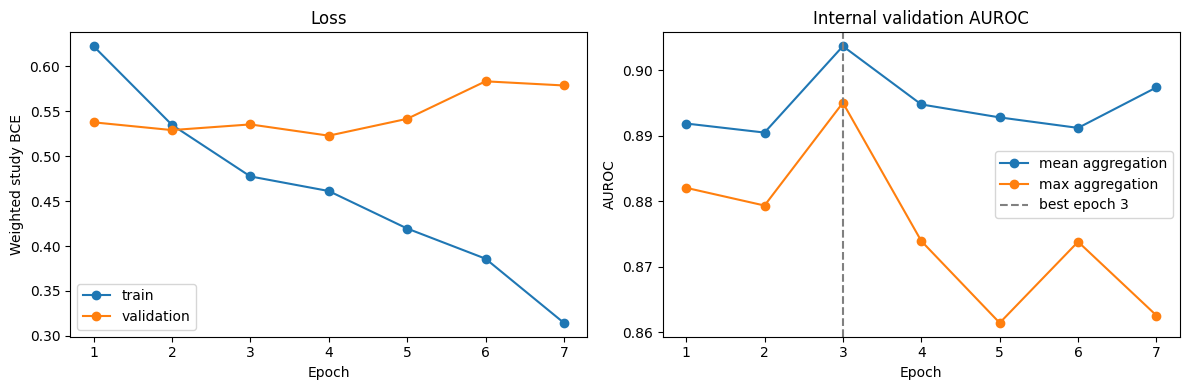

In [286]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train")
axes[0].plot(history["epoch"], history["validation_loss"], marker="o", label="validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted study BCE")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history["epoch"], history["validation_auroc_mean"], marker="o", label="mean aggregation")
axes[1].plot(history["epoch"], history["validation_auroc_max"], marker="o", label="max aggregation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUROC")
axes[1].set_title("Internal validation AUROC")
axes[1].legend()
plt.tight_layout()
curves_path = out_path(RUN_DIR, "training_curves.png")
plt.savefig(curves_path, dpi=160, bbox_inches="tight")
plt.show()

## Final validation predictions and aggregation choice

The best checkpoint is reloaded. Mean and max aggregation are compared **once** on internal validation
(as in the Phase-1 protocol); ties keep the mean.

In [287]:
checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
validation_frame, validation_views_pred = predict(model, validation_loader)

aggregation_scores = {
    "mean": roc_auc_score(validation_frame["label"], validation_frame["prob_mean"]),
    "max": roc_auc_score(validation_frame["label"], validation_frame["prob_max"]),
}
SELECTED_AGGREGATION = "max" if aggregation_scores["max"] > aggregation_scores["mean"] + 1e-6 else "mean"
validation_frame["abnormal_probability"] = validation_frame[f"prob_{SELECTED_AGGREGATION}"]
validation_frame.insert(0, "split", "validation")

y_true = validation_frame["label"].to_numpy(dtype=int)
y_score = validation_frame["abnormal_probability"].to_numpy(dtype=float)
ranking_metrics_b = {
    "split": "internal_validation",
    "model": "B",
    "aggregation": SELECTED_AGGREGATION,
    "auroc": float(roc_auc_score(y_true, y_score)),
    "auprc": float(average_precision_score(y_true, y_score)),
}
print("Aggregation AUROC:", {k: round(v, 4) for k, v in aggregation_scores.items()}, "-> selected:", SELECTED_AGGREGATION)
display(pd.DataFrame([ranking_metrics_b]))

Aggregation AUROC: {'mean': np.float64(0.9037), 'max': np.float64(0.895)} -> selected: mean


,split,model,aggregation,auroc,auprc
0,internal_validation,B,mean,0.903689,0.879105


## Fair comparison with Model A on the same validation studies

Model A's saved validation predictions (Notebook 03) are read, not changed. The AUROC difference uses a
patient-cluster bootstrap (all studies of a sampled patient stay together).

**Ablation note:** `DATA/BASELINE_MODEL_A` was overwritten on 18.10.2026 (C = 0.01), so this comparison is not against the frozen Model A and is not used in the ablation analysis (protocol §11).

,validation_studies,auroc_model_a,auroc_model_b,delta_auroc_b_minus_a,delta_ci95_lower,delta_ci95_upper,bootstrap_samples,note
0,691,0.888115,0.903689,0.015575,-0.001543,0.032611,1000,Internal validation; both models were selected...


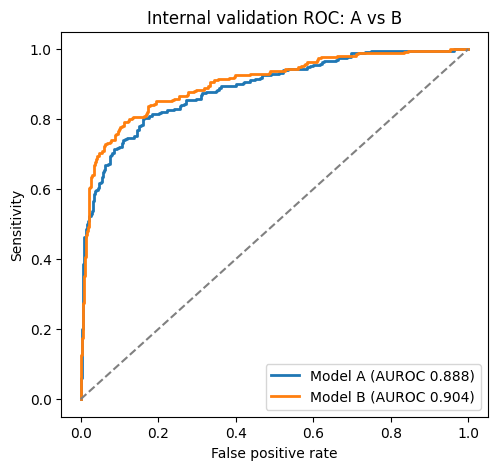

In [288]:
model_a_predictions = pd.read_csv(MODEL_A_DIR / "validation_predictions.csv")
assert set(model_a_predictions["study_id"].astype(str)) == set(validation_frame["study_id"]), "Study sets differ"
paired = validation_frame.merge(
    model_a_predictions[["study_id", "abnormal_probability"]].rename(columns={"abnormal_probability": "prob_model_a"}),
    on="study_id",
    validate="one_to_one",
)
auroc_a = roc_auc_score(paired["label"], paired["prob_model_a"])
auroc_b = roc_auc_score(paired["label"], paired["abnormal_probability"])


def paired_patient_bootstrap(frame, n_iterations=1000, seed=SEED):
    patients = frame["patient_id"].astype(str).to_numpy()
    unique = np.unique(patients)
    groups = [np.flatnonzero(patients == p) for p in unique]
    y = frame["label"].to_numpy(dtype=int)
    a = frame["prob_model_a"].to_numpy(dtype=float)
    b = frame["abnormal_probability"].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    deltas = []
    for _ in range(n_iterations):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(unique), len(unique))])
        if np.unique(y[idx]).size < 2:
            continue
        deltas.append(roc_auc_score(y[idx], b[idx]) - roc_auc_score(y[idx], a[idx]))
    return np.array(deltas)


deltas = paired_patient_bootstrap(paired)
comparison = {
    "validation_studies": int(len(paired)),
    "auroc_model_a": float(auroc_a),
    "auroc_model_b": float(auroc_b),
    "delta_auroc_b_minus_a": float(auroc_b - auroc_a),
    "delta_ci95_lower": float(np.quantile(deltas, 0.025)),
    "delta_ci95_upper": float(np.quantile(deltas, 0.975)),
    "bootstrap_samples": int(len(deltas)),
    "note": "Internal validation; both models were selected on this split, so this is a development comparison.",
}
display(pd.DataFrame([comparison]))

fig, ax = plt.subplots(figsize=(5.5, 5))
for column, name in [("prob_model_a", f"Model A (AUROC {auroc_a:.3f})"), ("abnormal_probability", f"Model B (AUROC {auroc_b:.3f})")]:
    fpr, tpr, _ = roc_curve(paired["label"], paired[column])
    ax.plot(fpr, tpr, linewidth=2, label=name)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("Sensitivity")
ax.set_title("Internal validation ROC: A vs B")
ax.legend(loc="lower right")
roc_path = out_path(RUN_DIR, "validation_roc_model_a_vs_b.png")
plt.savefig(roc_path, dpi=160, bbox_inches="tight")
plt.show()

## Save outputs for Notebooks 06 and 07

In [289]:
def sha256_of(path, chunk=1 << 20):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()


prediction_columns = ["split", "patient_id", "study_id", "label", "num_views", "abnormal_probability", "prob_mean", "prob_max"]
validation_frame[prediction_columns].to_csv(out_path(RUN_DIR, "validation_predictions.csv"), index=False)
validation_views_pred.to_csv(out_path(RUN_DIR, "validation_view_predictions.csv"), index=False)
history.to_csv(out_path(RUN_DIR, "training_log.csv"), index=False)
out_path(RUN_DIR, "validation_ranking_metrics.json").write_text(json.dumps(ranking_metrics_b, indent=2), encoding="utf-8")
out_path(RUN_DIR, "comparison_with_model_a.json").write_text(json.dumps(comparison, indent=2), encoding="utf-8")
out_path(RUN_DIR, "model_selection.json").write_text(json.dumps({
    "selection_split": "internal_validation",
    "monitor": CONFIG["monitor"],
    "best_epoch": int(best_epoch),
    "best_validation_auroc_mean": float(best_auroc),
    "aggregation_candidates": CONFIG["aggregation_candidates"],
    "aggregation_validation_auroc": aggregation_scores,
    "selected_aggregation": SELECTED_AGGREGATION,
}, indent=2), encoding="utf-8")

checkpoint_sha256 = sha256_of(BEST_CHECKPOINT)
out_path(RUN_DIR, "run_metadata.json").write_text(json.dumps({
    "model": f"Model B: ImageNet ResNet-18, trainable layers: {CONFIG['trainable_layers']}, study-level loss",
    "experiment": CONFIG["experiment"],
    "trainable_layers": CONFIG["trainable_layers"],
    "n_trainable_params": int(N_TRAINABLE),
    "frozen_blocks": FROZEN_NAMES,
    "frozen_bn_eval": True,
    "run_dir": str(RUN_DIR),
    "config": CONFIG,
    "positive_class_weight": POSITIVE_WEIGHT,
    "epochs_run": int(len(history)),
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if USE_AMP else None,
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "inputs": {
        "train_manifest": str(TRAIN_MANIFEST),
        "train_manifest_sha256": sha256_of(TRAIN_MANIFEST),
        "validation_manifest": str(VALIDATION_MANIFEST),
        "validation_manifest_sha256": sha256_of(VALIDATION_MANIFEST),
        "model_a_validation_predictions": str(MODEL_A_DIR / "validation_predictions.csv"),
    },
    "best_checkpoint": str(BEST_CHECKPOINT),
    "best_checkpoint_sha256": checkpoint_sha256,
    "official_mura_valid_read": False,
}, indent=2), encoding="utf-8")

for path in sorted(RUN_DIR.iterdir()):
    print("Saved:", path.name)
print()
print("RUN_ID =", repr(RUN_DIR.name), " <- record in experiments/ablation_finetune_depth/PROTOCOL.md §14")

Saved: best_model_b.pt
Saved: comparison_with_model_a.json
Saved: last_checkpoint.pt
Saved: model_selection.json
Saved: run_metadata.json
Saved: training_curves.png
Saved: training_log.csv
Saved: validation_predictions.csv
Saved: validation_ranking_metrics.json
Saved: validation_roc_model_a_vs_b.png
Saved: validation_view_predictions.csv

RUN_ID = 'run_20261020T215534Z'  <- record in experiments/ablation_finetune_depth/PROTOCOL.md §14


## After the run

Record the run id and the summary row above in `experiments/ablation_finetune_depth/PROTOCOL.md` §14 and save the executed copy under `experiments/ablation_finetune_depth/runs/`. Results of this experiment do not enter Notebook 06a: switching Model B to another arm needs a team decision, a new 06a freeze and a single 06b run (protocol §11).

In [290]:
# Protocol registry row (§14) and R0 reproducibility check (§6).
registry_row = {
    "arm": CONFIG["trainable_layers"],
    "seed": SEED,
    "run_id": RUN_DIR.name,
    "auroc": round(ranking_metrics_b["auroc"], 6),
    "auprc": round(ranking_metrics_b["auprc"], 6),
    "aggregation": SELECTED_AGGREGATION,
    "best_epoch": int(best_epoch),
    "epochs_run": int(len(history)),
    "n_trainable_params": int(N_TRAINABLE),
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
}
display(pd.DataFrame([registry_row]))

R0_REFERENCE_AUROC = 0.902042  # run_20261017T095546Z: seed 23, all layers (Notebook 05)
R0_TOLERANCE = 0.005           # protocol §6
if CONFIG["trainable_layers"] == "all" and SEED == 23:
    delta = ranking_metrics_b["auroc"] - R0_REFERENCE_AUROC
    verdict = ("PASS: the existing S4 runs stay the control" if abs(delta) <= R0_TOLERANCE
               else "FAIL: rerun all three S4 seeds (protocol §6)")
    print(f"R0 check: AUROC {ranking_metrics_b['auroc']:.6f} vs {R0_REFERENCE_AUROC:.6f} (delta {delta:+.6f}) -> {verdict}")

,arm,seed,run_id,auroc,auprc,aggregation,best_epoch,epochs_run,n_trainable_params,gpu,torch
0,layer4+fc,202,run_20261020T215534Z,0.903689,0.879105,mean,3,7,8394241,Tesla T4,2.11.0+cu130
